In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("data/Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
display(df.head())
print("Dataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())
print("\nColumn Names:")
print(df.columns.tolist())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [4]:
print("Missing values before cleaning:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
for column in features:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df = df.dropna(subset=features).copy()
print("\nMissing values after cleaning:")
print(df[features].isnull().sum())
print("\nDataset shape after cleaning:", df.shape)

Missing values before cleaning:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Missing values after cleaning:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Dataset shape after cleaning: (200, 5)


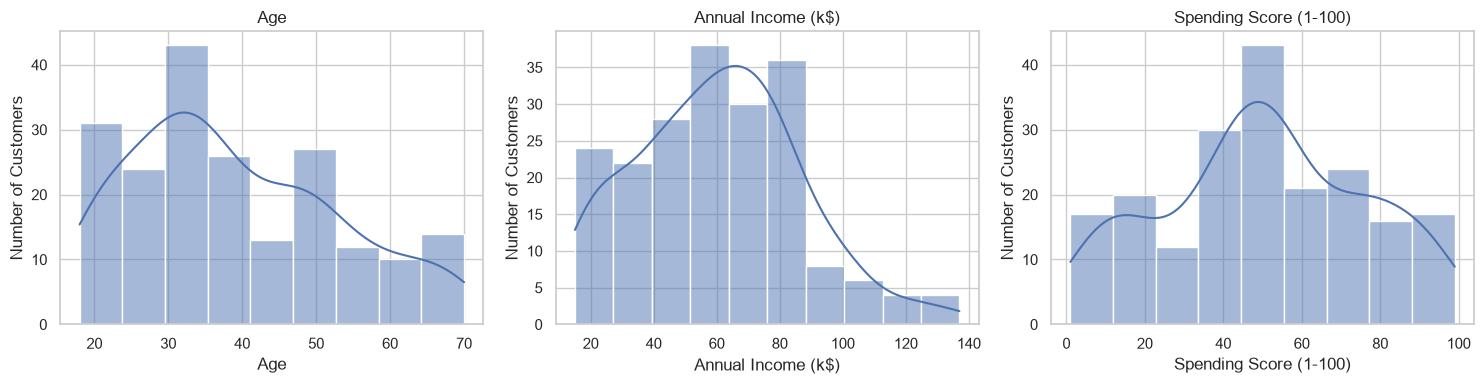

In [5]:
plt.figure(figsize=(15, 4))
for i, column in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.histplot(
        df[column],
        kde=True
    )
    plt.title(column)
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    "outputs/feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

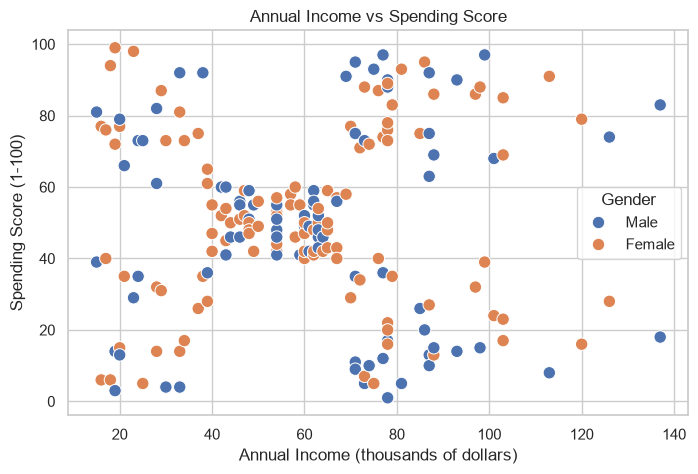

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1-100)")
plt.savefig(
    "outputs/income_spending_eda.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [7]:
X = df[features].copy()
print("Selected features:")
display(X.head())
print("\nShape of feature data:", X.shape)

Selected features:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40



Shape of feature data: (200, 3)


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data:")
display(X.head())
print("\nScaled data:")
print(X_scaled[:5])
print("\nScaled data shape:", X_scaled.shape)

Original data:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40



Scaled data:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]

Scaled data shape: (200, 3)


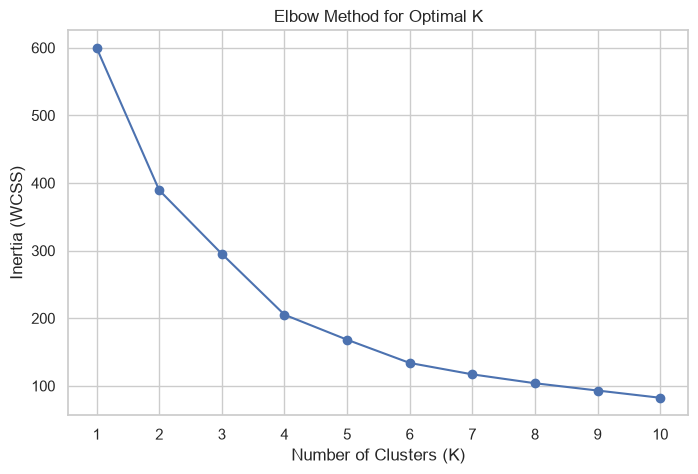

In [9]:
inertia_values = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.savefig(
    "outputs/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [10]:
silhouette_values = []
for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    cluster_labels = model.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled,
        cluster_labels
    )
    silhouette_values.append(score)
silhouette_results = pd.DataFrame({
    "K": range(2, 11),
    "Silhouette Score": silhouette_values
})
print("Silhouette Scores:")
display(silhouette_results.round(4))

Silhouette Scores:


,K,Silhouette Score
0,2,0.3355
1,3,0.3578
2,4,0.4040
3,5,0.4166
4,6,0.4284
5,7,0.4172
6,8,0.4082
7,9,0.4177
8,10,0.4066


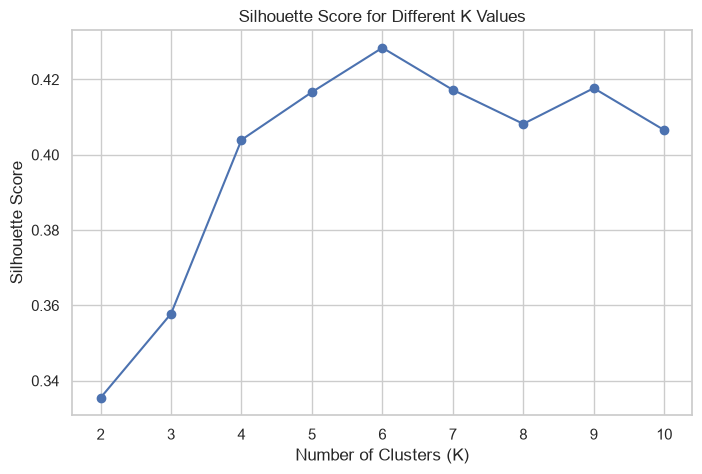

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_results["K"],
    silhouette_results["Silhouette Score"],
    marker="o"
)
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.savefig(
    "outputs/silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [12]:
chosen_k = 5
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("K-Means model trained successfully!")
print("Number of clusters:", chosen_k)
print("\nNumber of customers in each cluster:")
print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)

K-Means model trained successfully!
Number of clusters: 5

Number of customers in each cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64


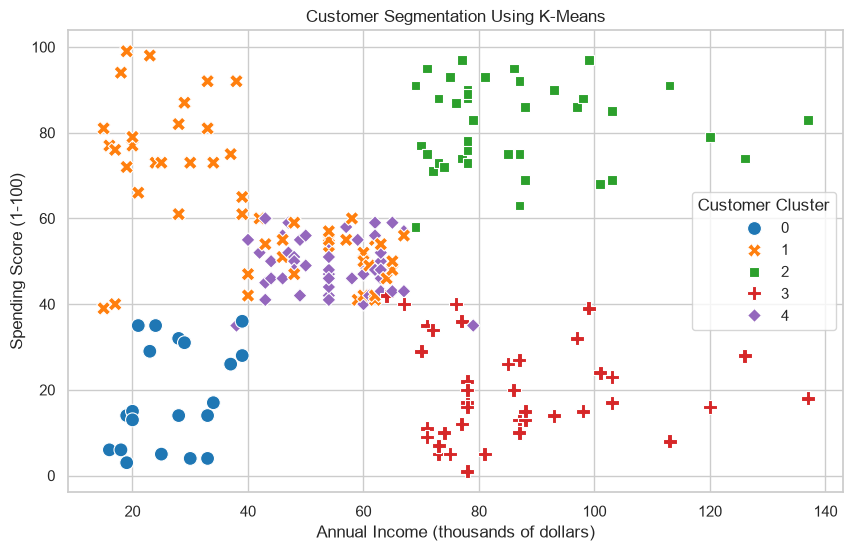

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100,
    style="Cluster"
)
plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.savefig(
    "outputs/customer_clusters.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)
print("CUSTOMER CLUSTER PROFILES")
display(cluster_profile)

CUSTOMER CLUSTER PROFILES


,Customer_Count,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,20,46.25,26.75,18.35
1,54,25.19,41.09,62.24
2,40,32.88,86.10,81.53
3,39,39.87,86.10,19.36
4,47,55.64,54.38,48.85


In [15]:
def label_spending(score):
    if score <= 40:
        return "Low Spenders"
    elif score <= 60:
        return "Medium Spenders"
    else:
        return "High Spenders"

cluster_profile["Spending_Group"] = (
    cluster_profile["Average_Spending"].apply(label_spending)
)
print("CUSTOMER SEGMENT ANALYSIS")
display(cluster_profile)

CUSTOMER SEGMENT ANALYSIS


,Customer_Count,Average_Age,Average_Income,Average_Spending,Spending_Group
Cluster,,,,,
0,20,46.25,26.75,18.35,Low Spenders
1,54,25.19,41.09,62.24,High Spenders
2,40,32.88,86.10,81.53,High Spenders
3,39,39.87,86.10,19.36,Low Spenders
4,47,55.64,54.38,48.85,Medium Spenders


In [16]:
spending_labels = cluster_profile["Spending_Group"].to_dict()
df["Spending_Group"] = df["Cluster"].map(spending_labels)
print("Customer assignments:")
display(df.head(10))

Customer assignments:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Spending_Group
0,1,Male,19,15,39,1,High Spenders
1,2,Male,21,15,81,1,High Spenders
2,3,Female,20,16,6,0,Low Spenders
3,4,Female,23,16,77,1,High Spenders
4,5,Female,31,17,40,1,High Spenders
5,6,Female,22,17,76,1,High Spenders
6,7,Female,35,18,6,0,Low Spenders
7,8,Female,23,18,94,1,High Spenders
8,9,Male,64,19,3,0,Low Spenders
9,10,Female,30,19,72,1,High Spenders


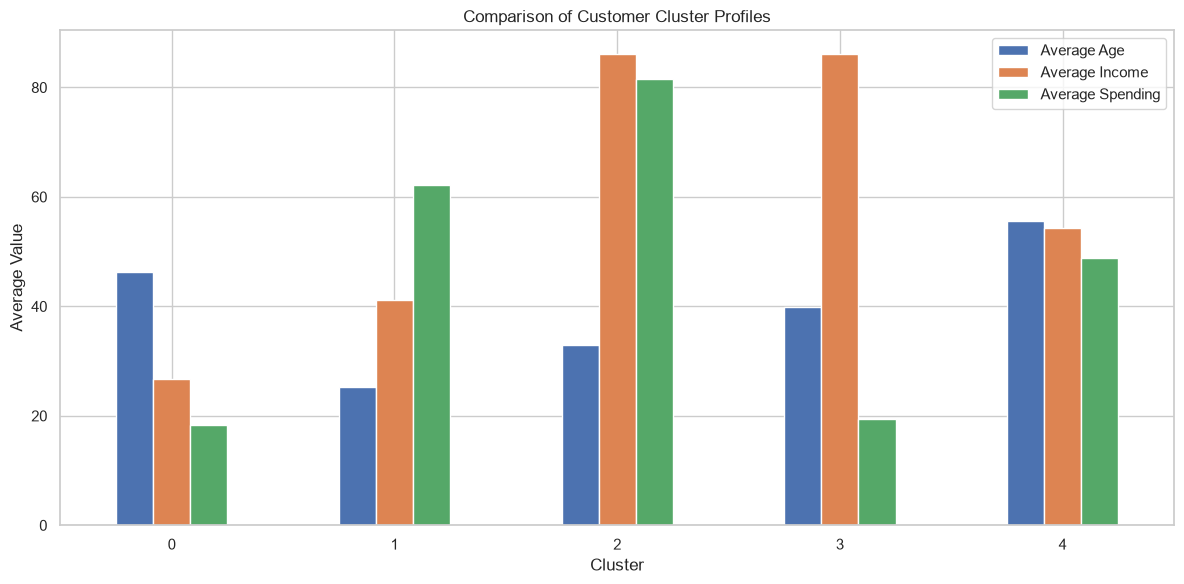

In [17]:
cluster_profile[
    ["Average_Age", "Average_Income", "Average_Spending"]
].plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Comparison of Customer Cluster Profiles")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(["Average Age", "Average Income", "Average Spending"])
plt.tight_layout()
plt.savefig(
    "outputs/cluster_profile_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
final_silhouette = silhouette_score(
    X_scaled,
    df["Cluster"]
)
print("FINAL MODEL EVALUATION")
print("----------------------")
print("Number of clusters:", chosen_k)
print("Silhouette Score:", round(final_silhouette, 4))
print("Total customers:", len(df))

FINAL MODEL EVALUATION
----------------------
Number of clusters: 5
Silhouette Score: 0.4166
Total customers: 200


In [19]:
df.to_csv(
    "outputs/customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/cluster_profiles.csv"
)

centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)
centers_df = pd.DataFrame(
    centers_original,
    columns=features
)
centers_df.insert(
    0,
    "Cluster",
    range(chosen_k)
)

centers_df.to_csv(
    "outputs/cluster_centers.csv",
    index=False
)

silhouette_results.to_csv(
    "outputs/silhouette_results.csv",
    index=False
)
print("All results saved successfully!")

All results saved successfully!


In [20]:
print("=" * 45)
print("CUSTOMER SEGMENTATION USING K-MEANS")
print("=" * 45)
print("Total customers:", len(df))
print("Features used:", ", ".join(features))
print("Number of clusters:", chosen_k)
print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())
print("\nAverage spending score by cluster:")
print(
    df.groupby("Cluster")["Spending Score (1-100)"]
      .mean()
      .round(2)
)
print("\nFinal Silhouette Score:", round(final_silhouette, 4))
print("\nProject completed successfully!")

CUSTOMER SEGMENTATION USING K-MEANS
Total customers: 200
Features used: Age, Annual Income (k$), Spending Score (1-100)
Number of clusters: 5

Customers in each cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

Average spending score by cluster:
Cluster
0    18.35
1    62.24
2    81.53
3    19.36
4    48.85
Name: Spending Score (1-100), dtype: float64

Final Silhouette Score: 0.4166

Project completed successfully!
